# Fan et al. 2023: the source files

Attempted handwriting from BrainGate2 participant T5 over 26 days in a year. The recordings come in two deposits:

- **Dryad** (`doi:10.5061/dryad.hqbzkh1p6`), the authors' release: one `.mat` file per day and block kind for the 21 days up to 2023-02-28. The 11 seed days are open-loop. On the 10 online days a decoder ran live, either frozen (no-recalibration blocks) or updated by CORP (recalibration blocks).
- **DANDI 000950** (FALCON H2), a benchmark cut from those files, plus the first three trials of 5 later days that are not on Dryad.

This notebook opens both, shows how the FALCON files relate to the Dryad ones byte for byte, and looks at the trials, the firing rates across days and the online decoder's outputs.

The setup cell builds the Study and calls `download()`, which fetches both deposits on the first run (Dryad needs `NEURALFETCH_DRYAD_TOKEN`) and returns immediately afterwards.

In [1]:
from dotenv import load_dotenv
import hashlib
import struct

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from neuralshed.datasets.fan_2023 import study, utils
from neuralshed.datasets.utils import dataset_dir

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# reads ./.env into os.environ
load_dotenv()

# the Study base appends the class-name folder
s = study.Fan2023Handwriting(path=dataset_dir("fan_2023") / "data")
s.download()
ROOT = s.path
FALCON = ROOT / utils.DANDISET_ID

# the files the Study reads
SOURCES = pd.DataFrame(utils.list_sources(ROOT))


def falcon_file(split, date):
    """The FALCON NWB of one split and day."""
    (path,) = [
        p
        for p in (FALCON / f"sub-T5-{split}").glob("*.nwb")
        if not p.name.startswith("._") and utils.date_of(p) == date
    ]
    return path


def digest(x):
    return hashlib.sha256(np.ascontiguousarray(x).tobytes()).hexdigest()


def n_records(folder):
    """Number of records in the tfrecord files of a folder (8-byte length, 4-byte crc, data, 4-byte crc)."""
    n = 0
    for f in folder.glob("*.tfrecord"):
        if f.name.startswith("._"):
            continue
        data = f.read_bytes()
        i = 0
        while i < len(data):
            (size,) = struct.unpack("<Q", data[i : i + 8])
            i += 12 + size + 4
            n += 1
    return n


def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev = d[0]
        d[0] = i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[-1]


print("files read by the Study:", len(SOURCES))

2026-10-14 16:40:49 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/fan_2023/data/Fan2023Handwriting.


2026-10-14 16:40:49 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/fan_2023/data/Fan2023Handwriting (skipped 0 non-owned items).


files read by the Study: 36


## 1. Files and days

Each day has one Dryad file per block kind, two on the online days. The 5 days after 2023-02-28 exist only as FALCON `held-out-calib` NWB files with three trials each.

In [2]:
SOURCES["deposit"] = np.where(SOURCES.path.str.endswith(".mat"), "dryad", "dandi")
SOURCES["trials"] = [utils.count_trials(ROOT / p) for p in SOURCES.path]
SOURCES["MB"] = [(ROOT / p).stat().st_size / 1e6 for p in SOURCES.path]

display(
    SOURCES.groupby(["deposit", "block_kind", "loop_type"]).agg(
        files=("date", "size"),
        first_day=("date", "min"),
        last_day=("date", "max"),
        trials=("trials", "sum"),
    )
)
SOURCES.pivot_table(
    index="date", columns="block_kind", values="trials", aggfunc="sum"
).fillna(0).astype(int).T

files   first_day    last_day  trials
deposit block_kind       loop_type                                       
dandi   recalibration    closed         5  2023-04-17  2023-10-09      15
dryad   no_recalibration closed        10  2022-09-29  2023-02-28     199
        recalibration    closed        10  2022-09-29  2023-02-28     377
        seed             open          11  2022-05-18  2022-09-01     739

date,2022-05-18,2022-05-23,2022-05-25,2022-06-01,2022-06-03,2022-06-06,2022-06-08,2022-06-13,2022-06-15,2022-06-22,2022-09-01,2022-09-29,2022-10-06,2022-10-18,2022-10-25,2022-10-27,2022-11-01,2022-11-03,2022-12-08,2022-12-15,2023-02-28,2023-04-17,2023-05-31,2023-06-28,2023-08-16,2023-10-09
block_kind,,,,,,,,,,,,,,,,,,,,,,,,,,
no_recalibration,0,0,0,0,0,0,0,0,0,0,0,20,20,20,20,20,20,20,20,19,20,0,0,0,0,0
recalibration,0,0,0,0,0,0,0,0,0,0,0,40,40,40,37,40,40,40,40,20,40,3,3,3,3,3
seed,50,80,60,80,80,78,41,80,60,80,50,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. A Dryad file

`tx_feats` holds one `(n_bins, 192)` float32 array per trial, the 20 ms threshold-crossing counts of the go period (the README of the deposit). `sentences` and `blocks` run in parallel. Online files add the live decoder's raw output (`rnn_decoded`) and its language-model-corrected output (`lm_decoded`).

In [3]:
seed = utils.read_mat(ROOT / SOURCES.query("block_kind == 'seed'").path.iloc[0])
online = utils.read_mat(
    ROOT
    / SOURCES.query("block_kind == 'recalibration' and deposit == 'dryad'").path.iloc[
        -1
    ]
)

print("seed fields  :", sorted(seed))
print("online fields:", sorted(online))
print(
    "first trial  :",
    seed["tx_feats"][0].shape,
    seed["tx_feats"][0].dtype,
    "| block",
    seed["blocks"][0],
)
print(
    "values       :",
    float(min(x.min() for x in seed["tx_feats"])),
    "-",
    float(max(x.max() for x in seed["tx_feats"])),
    "| integers:",
    all(np.array_equal(x, np.round(x)) for x in seed["tx_feats"]),
)

pd.DataFrame({k: online[k][:4] for k in ("sentences", "rnn_decoded", "lm_decoded")})

seed fields  : ['blocks', 'sentences', 'tx_feats']
online fields: ['blocks', 'lm_decoded', 'rnn_decoded', 'sentences', 'tx_feats']
first trial  : (2687, 192) float32 | block 14
values       : 0.0 - 11.0 | integers: True


,sentences,rnn_decoded,lm_decoded
0,"when>alexander>brandel>rose>to>speak,>the>hall...",leb>alexarder>bhorde>>ras>nealt>hahall>toeome>...,when>alexander>blonde>has>real>have>become>sil...
1,there>was>a>slight>nervous>twitch>in>the>regio...,there>was>a>slight>hervous>twitch>in>the>neaio...,there>was>a>slight>nervous>twitch>in>the>regio...
2,or>borrow>some>money>from>someone>and>go>home>...,or>borrow>some>money>from>somedne>and>go>home>...,or>borrow>some>money>from>someone>and>go>home>...
3,"i'm>not>advising>you,>she>said~","m>hot>adrising>you,>she>said~","im>not>advising>you,>she>said~"


## 3. A FALCON file

The NWB files store the same per-trial arrays end to end in one `binned_spikes` array, on a clock with a synthetic 10 s spacer between trials (`trial_offset = 10 / 0.02` bins in FALCON's converter). `utils.trial_bins` finds each trial's rows from the timestamps and raises if the clips do not tile the array.

In [4]:
import h5py

with h5py.File(falcon_file("held-out-calib", "2023-04-17"), "r") as h5:
    timestamps = h5["acquisition/binned_spikes/timestamps"][:]
    trials = utils.read_trials(h5)

print(
    "timestamp steps (s):",
    pd.Series(np.round(np.diff(timestamps), 3)).value_counts().to_dict(),
)
trials.join(utils.trial_bins(timestamps, trials))

timestamp steps (s): {0.02: 3966, 10.02: 2}


,start_time,stop_time,cue,block_num,bin_start,bin_stop
id,,,,,,
0,0.00,18.74,what>about>transfers?,5,0,938
1,28.76,60.98,"unquestionably,>blanche>loved>stanley~",5,938,2550
2,71.00,99.36,"we'll>work>hard,>mr~>morgan~",5,2550,3969


## 4. FALCON is cut from the Dryad files

For every held-in day, FALCON's converter kept the first `n - int(0.4 n)` trials of the day's seed or recalibration file as `held-in-calib`, withheld the rest for its evaluation server, and copied the first two again as `held-in-minival`. The cell checks this byte for byte on all 21 days, together with the cues and blocks. It also hashes every trial of both deposits: no no-recalibration trial appears in any FALCON file, every FALCON trial except the 15 `held-out-calib` ones is a Dryad trial, and no array repeats on Dryad. The Study therefore reads Dryad for these days and FALCON only for the 5 later ones.

In [5]:
falcon_digests = {}
for p in FALCON.rglob("*.nwb"):
    if not p.name.startswith("._"):
        for x in utils.read_nwb(p)["tx_feats"]:
            falcon_digests.setdefault(digest(x), []).append(p.parent.name)
dryad_digests = [
    digest(x)
    for p in SOURCES.query("deposit == 'dryad'").path
    for x in utils.read_mat(ROOT / p)["tx_feats"]
]

rows = []
for src in SOURCES.query(
    "deposit == 'dryad' and block_kind != 'no_recalibration'"
).itertuples():
    dryad = utils.read_mat(ROOT / src.path)
    calib = utils.read_nwb(falcon_file("held-in-calib", src.date))
    minival = utils.read_nwb(falcon_file("held-in-minival", src.date))
    n = len(dryad["tx_feats"])
    k = len(calib["tx_feats"])
    rows.append(
        {
            "date": src.date,
            "block_kind": src.block_kind,
            "dryad trials": n,
            "falcon calib": k,
            "n - int(0.4 n)": n - int(0.4 * n),
            "identical arrays": sum(
                x.tobytes() == y.tobytes()
                for x, y in zip(calib["tx_feats"], dryad["tx_feats"])
            ),
            "same cues and blocks": calib["sentences"] == dryad["sentences"][:k]
            and calib["blocks"] == dryad["blocks"][:k],
            "minival = first two": [x.tobytes() for x in minival["tx_feats"]]
            == [x.tobytes() for x in dryad["tx_feats"][:2]],
            "withheld trials": n - k,
        }
    )
held_in = pd.DataFrame(rows)

no_recal_in_falcon = sum(
    digest(x) in falcon_digests
    for p in SOURCES.query("block_kind == 'no_recalibration'").path
    for x in utils.read_mat(ROOT / p)["tx_feats"]
)
print(
    "days where every calib trial is a byte copy:",
    int((held_in["identical arrays"] == held_in["falcon calib"]).sum()),
    "of",
    len(held_in),
)
print(
    "count rule holds on every day:",
    bool((held_in["falcon calib"] == held_in["n - int(0.4 n)"]).all()),
)
print("no-recalibration trials found in FALCON files:", no_recal_in_falcon)
print(
    "trials on Dryad only (withheld by FALCON):", int(held_in["withheld trials"].sum())
)
print(
    "FALCON trials not on Dryad:",
    pd.Series(
        [
            f
            for h, files in falcon_digests.items()
            if h not in set(dryad_digests)
            for f in files
        ]
    )
    .value_counts()
    .to_dict(),
)
print(
    "Dryad trials:", len(dryad_digests), "| distinct arrays:", len(set(dryad_digests))
)
held_in

days where every calib trial is a byte copy: 21 of 21
count rule holds on every day: True
no-recalibration trials found in FALCON files: 0
trials on Dryad only (withheld by FALCON): 445
FALCON trials not on Dryad: {'sub-T5-held-out-calib': 15}
Dryad trials: 1315 | distinct arrays: 1315


,date,block_kind,dryad trials,falcon calib,n - int(0.4 n),identical arrays,same cues and blocks,minival = first two,withheld trials
0,2022-05-18,seed,50,30,30,30,True,True,20
1,2022-05-23,seed,80,48,48,48,True,True,32
2,2022-05-25,seed,60,36,36,36,True,True,24
3,2022-06-01,seed,80,48,48,48,True,True,32
4,2022-06-03,seed,80,48,48,48,True,True,32
5,2022-06-06,seed,78,47,47,47,True,True,31
6,2022-06-08,seed,41,25,25,25,True,True,16
7,2022-06-13,seed,80,48,48,48,True,True,32
8,2022-06-15,seed,60,36,36,36,True,True,24
9,2022-06-22,seed,80,48,48,48,True,True,32


## 5. The authors' split

The Dryad deposit also holds the same trials as tfrecords, the input of the authors' training code, in a `train` and a `test` folder per day. On each seed day the test folder holds the last 10 trials, and CORP's seed-model training reads it as validation. The online days put every trial in `train`. `utils.corp_split` reproduces the partition, and the Study carries it as `corp_split`. The cell compares the record counts.

In [6]:
rows = []
for src in SOURCES.query("deposit == 'dryad'").itertuples():
    mat = ROOT / src.path
    n = utils.count_trials(mat)
    labels = [utils.corp_split(src.block_kind, i, n) for i in range(n)]
    records = mat.parent.parent / "tfrecords" / mat.stem
    rows.append(
        {
            "date": src.date,
            "block_kind": src.block_kind,
            "train records": n_records(records / "train"),
            "test records": n_records(records / "test"),
            "corp_split train": labels.count("train"),
            "corp_split test": labels.count("test"),
        }
    )
corp = pd.DataFrame(rows)
print(
    "counts agree on every file:",
    bool(
        (corp["train records"] == corp["corp_split train"]).all()
        and (corp["test records"] == corp["corp_split test"]).all()
    ),
)
corp.groupby("block_kind")[["train records", "test records"]].sum()

counts agree on every file: True


,train records,test records
block_kind,,
no_recalibration,199,0
recalibration,377,0
seed,629,110


## 6. Trials and cues

T5 copies the sentence letter by letter and says when he has finished, so the length of a trial follows the sentence. The cue writes a space as `>` and a period as `~`.

In [7]:
rows = []
for src in SOURCES.itertuples():
    trials = utils.read_source(ROOT, src.path)
    for i, (x, cue) in enumerate(zip(trials["tx_feats"], trials["sentences"])):
        rows.append(
            {
                "date": src.date,
                "block_kind": src.block_kind,
                "trial_id": i,
                "seconds": len(x) / utils.BIN_RATE_HZ,
                "chars": len(cue),
            }
        )
trials = pd.DataFrame(rows)

print("trials:", len(trials), "| days:", trials.date.nunique())
print(
    "seconds per trial: median",
    round(trials.seconds.median(), 1),
    "| range",
    round(trials.seconds.min(), 1),
    "-",
    round(trials.seconds.max(), 1),
)
print(
    "characters per second: median", round((trials.chars / trials.seconds).median(), 2)
)

trials: 1330 | days: 26
seconds per trial: median 40.3 | range 7.4 - 98.5
characters per second: median 1.02


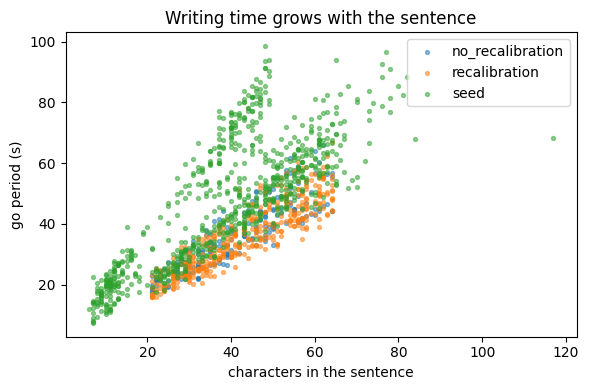

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
for kind, group in trials.groupby("block_kind"):
    ax.scatter(group.chars, group.seconds, s=8, alpha=0.5, label=kind)
ax.set(
    xlabel="characters in the sentence",
    ylabel="go period (s)",
    title="Writing time grows with the sentence",
)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Firing rates across days

Mean rate per channel for each day, against the median profile of the 21 Dryad days. Three days depart from the rest: 2023-10-09 fires about 12 times more, with nearly no silent bins and a per-channel profile unrelated to the other days, and 2023-02-28 and 2023-08-16 have a tenth of their channels far above their usual rate. The `Study` marks them `valid=False` (`utils.INVALID_DAYS`).

In [9]:
rates = {}
zeros = {}
for date, group in SOURCES.groupby("date"):
    x = np.concatenate(
        [np.concatenate(utils.read_source(ROOT, p)["tx_feats"]) for p in group.path]
    )
    rates[date] = x.mean(axis=0) * utils.BIN_RATE_HZ
    zeros[date] = float((x == 0).mean())
rates = pd.DataFrame(rates).T

reference = rates.loc[rates.index <= "2023-02-28"].median()
ratio = rates / reference.clip(lower=0.5)
days = pd.DataFrame(
    {
        "mean rate (Hz)": rates.mean(axis=1),
        "zero bins": pd.Series(zeros),
        "corr with Dryad median": rates.apply(
            lambda r: np.corrcoef(r, reference)[0, 1], axis=1
        ),
        "90th pct ratio": ratio.quantile(0.9, axis=1),
        "flagged": rates.index.isin(list(utils.INVALID_DAYS)),
    }
)
days.round(2).tail(8)

,mean rate (Hz),zero bins,corr with Dryad median,90th pct ratio,flagged
2022-12-08,8.900000,0.87,0.82,1.92,False
2022-12-15,10.110000,0.86,0.77,2.52,False
2023-02-28,16.790001,0.75,0.55,35.05,True
2023-04-17,14.610000,0.80,0.60,11.86,False
2023-05-31,10.450000,0.84,0.64,6.30,False
2023-06-28,11.150000,0.84,0.73,6.44,False
2023-08-16,24.440001,0.67,0.59,37.92,True
2023-10-09,128.029999,0.13,-0.09,288.84,True


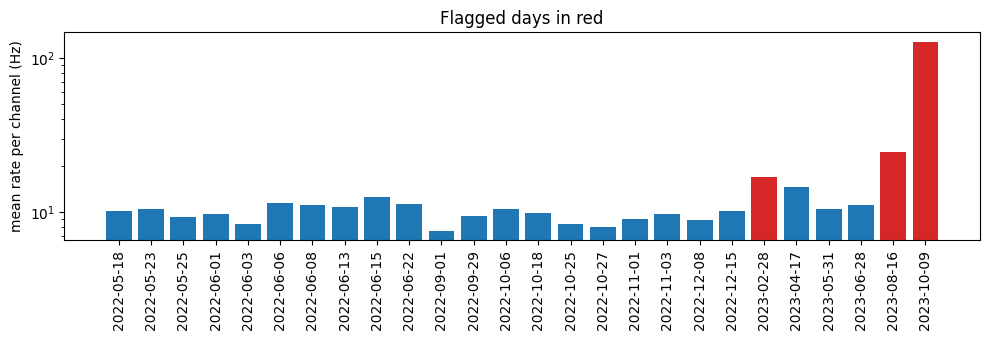

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(
    days.index,
    days["mean rate (Hz)"],
    color=np.where(days.flagged, "tab:red", "tab:blue"),
)
ax.set_yscale("log")
ax.set(ylabel="mean rate per channel (Hz)", title="Flagged days in red")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

## 8. The online decoder's outputs

On the 10 online Dryad days each trial also carries what the live system decoded. The character error rate of `lm_decoded` against the cue, per day and block kind, is the comparison the paper is about: a frozen seed decoder (no recalibration) against one CORP keeps updating.

In [11]:
rows = []
for src in SOURCES.query("deposit == 'dryad' and block_kind != 'seed'").itertuples():
    trials = utils.read_mat(ROOT / src.path)
    for key in ("rnn_decoded", "lm_decoded"):
        edits = sum(
            levenshtein(utils.decode_cue(d), utils.decode_cue(c))
            for d, c in zip(trials[key], trials["sentences"])
        )
        chars = sum(len(c) for c in trials["sentences"])
        rows.append(
            {
                "date": src.date,
                "block_kind": src.block_kind,
                "output": key,
                "CER": edits / chars,
            }
        )
online_cer = pd.DataFrame(rows).pivot_table(
    index="date", columns=["output", "block_kind"], values="CER"
)
online_cer.round(3)

output           lm_decoded                    rnn_decoded              
block_kind no_recalibration recalibration no_recalibration recalibration
date                                                                    
2022-09-29            0.021         0.012            0.114         0.036
2022-10-06            0.036         0.027            0.182         0.075
2022-10-18            0.058         0.024            0.234         0.077
2022-10-25            0.088         0.025            0.309         0.076
2022-10-27            0.161         0.013            0.326         0.065
2022-11-01            0.124         0.012            0.274         0.047
2022-11-03            0.094         0.013            0.333         0.046
2022-12-08            0.050         0.022            0.237         0.044
2022-12-15            0.104         0.009            0.297         0.045
2023-02-28            0.047         0.019            0.256         0.058

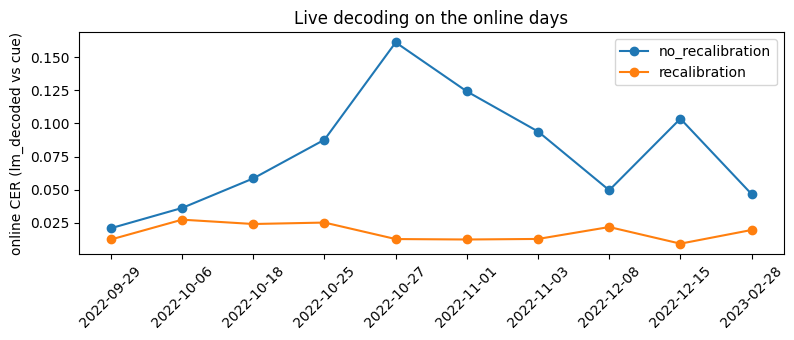

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for kind in ("no_recalibration", "recalibration"):
    ax.plot(online_cer.index, online_cer[("lm_decoded", kind)], marker="o", label=kind)
ax.set(
    ylabel="online CER (lm_decoded vs cue)", title="Live decoding on the online days"
)
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

## Notes

- **Threshold.** -4.5 x the standard deviation of the 300 Hz highpassed voltage, 20 ms bins (Fan et al. 2023). The deposit README writes "-4.5 RMS". The counts are integers stored as float32.
- **Not in either deposit.** The delay period, the time between trials, character timing, the warm-up blocks of the online days, and FALCON's evaluation trials of the 5 later days.
- Next: [`02_explore_study.ipynb`](02_explore_study.ipynb) builds the events table from these files.